Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OpenCV 5.0.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 255
piksel (y=100, x=200) dalam urutan BGR: [161 211 178]


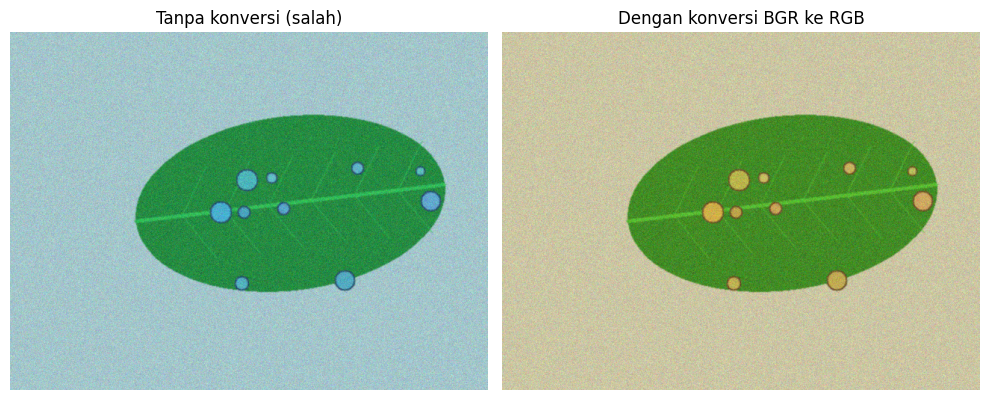

Hasil disimpan di: /content/drive/MyDrive/simuteh-2330511089-/hasil/b1_bgr_rgb.png


In [18]:

# B1 - LINGKUNGAN DAN PEMERIKSAAN CITRA

from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import cv2
import numpy as np
import skimage
import matplotlib.pyplot as plt

# Lokasi project di Google Drive
PROJECT = "/content/drive/MyDrive/simuteh-2330511089-"
SRC = os.path.join(PROJECT, "src")
DATA = os.path.join(PROJECT, "data", "sintetis")
HASIL = os.path.join(PROJECT, "hasil")

# Pastikan folder src dapat ditemukan Python
sys.path.insert(0, SRC)

# Muat ulang utils_cv agar menggunakan file terbaru
if "utils_cv" in sys.modules:
    del sys.modules["utils_cv"]

from utils_cv import baca, tampil

# Informasi versi library
print(
    "OpenCV", cv2.__version__,
    "| NumPy", np.__version__,
    "| scikit-image", skimage.__version__
)

# Baca citra teh_041.png
img_path = os.path.join(DATA, "citra", "teh_041.png")
img = baca(img_path)

# Informasi citra
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

# Tampilkan citra TANPA dan DENGAN konversi BGR ke RGB
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Tanpa konversi (salah)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")
plt.axis("off")

plt.tight_layout()

# Simpan hasil ke folder hasil
os.makedirs(HASIL, exist_ok=True)
output_path = os.path.join(HASIL, "b1_bgr_rgb.png")
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("Hasil disimpan di:", output_path)


Bagi petani dan petugas pemeriksa kualitas daun teh yang kesulitan mengidentifikasi serta menilai tingkat bercak pada daun secara konsisten, kami membangun SIMUTEH, yaitu sistem analisis citra daun teh yang menerima citra digital daun teh dan menghasilkan informasi kondisi daun, tingkat keparahan bercak, serta hasil analisis berdasarkan pengolahan citra, sehingga proses pemeriksaan kualitas daun teh dapat dilakukan dengan lebih objektif, konsisten, dan efisien.

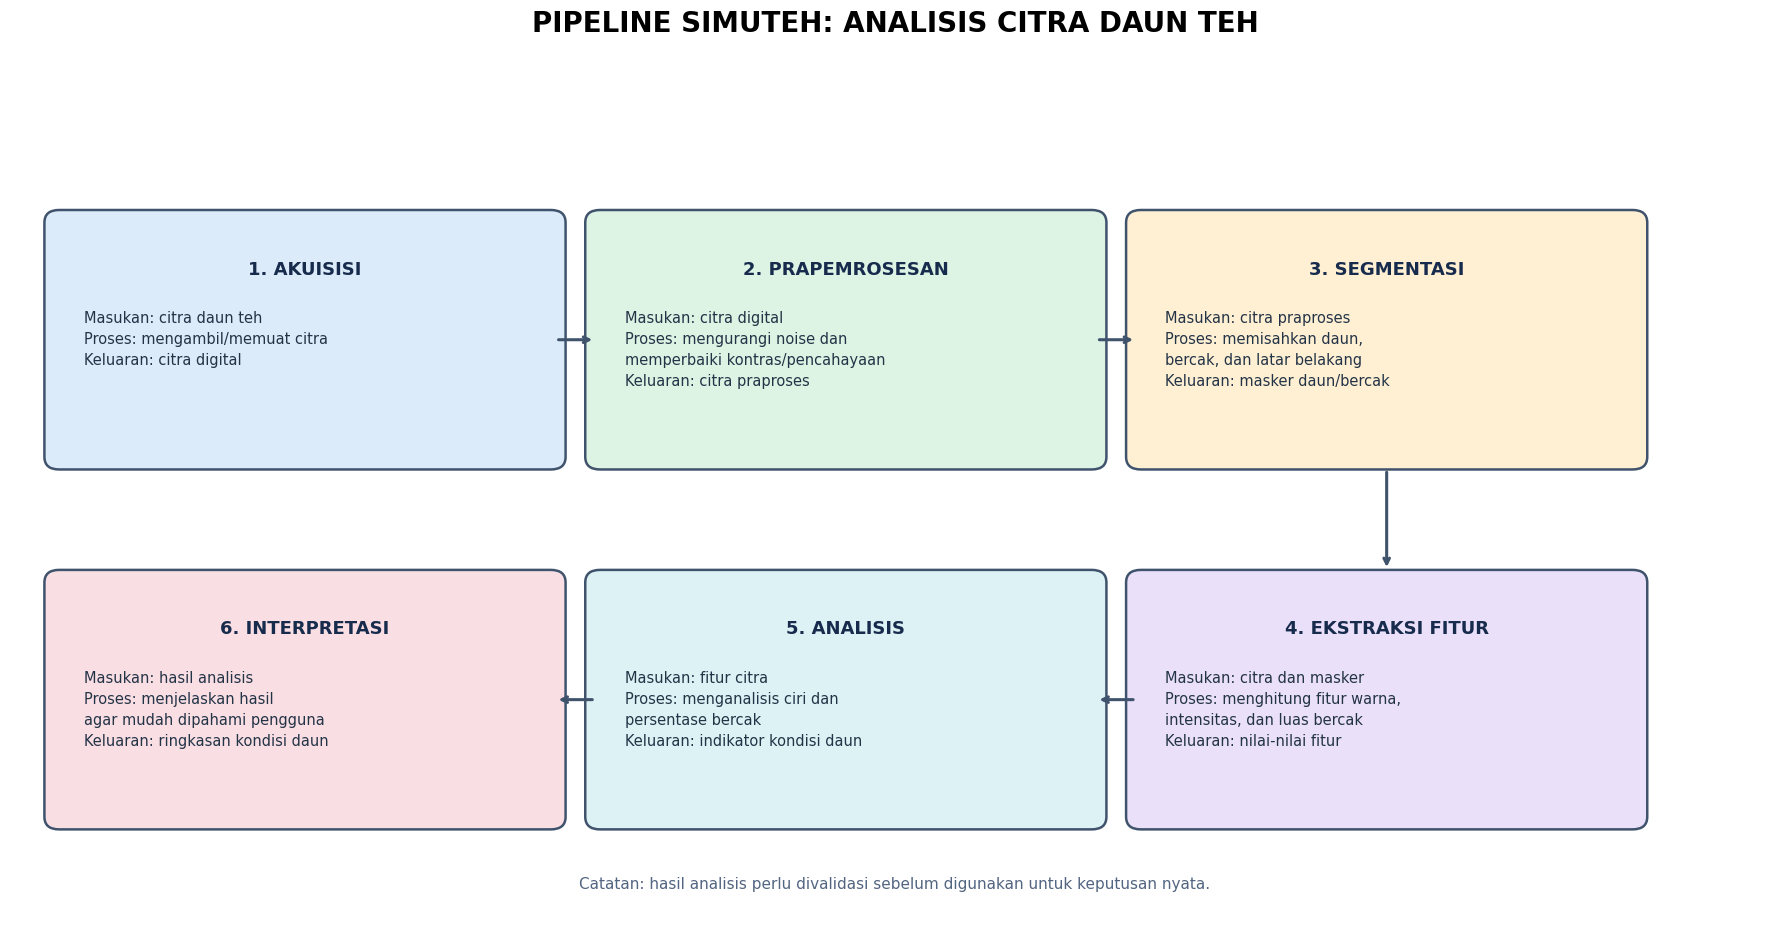

Diagram tersimpan di: /content/drive/MyDrive/simuteh-2330511089-/hasil/b1_pipeline.png


In [19]:
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Lokasi penyimpanan di Google Drive
PROJECT = "/content/drive/MyDrive/simuteh-2330511089-"
HASIL = os.path.join(PROJECT, "hasil")
os.makedirs(HASIL, exist_ok=True)

tahapan = [
    ("1. AKUISISI",
     "Masukan: citra daun teh\nProses: mengambil/memuat citra\nKeluaran: citra digital"),
    ("2. PRAPEMROSESAN",
     "Masukan: citra digital\nProses: mengurangi noise dan\nmemperbaiki kontras/pencahayaan\nKeluaran: citra praproses"),
    ("3. SEGMENTASI",
     "Masukan: citra praproses\nProses: memisahkan daun,\nbercak, dan latar belakang\nKeluaran: masker daun/bercak"),
    ("4. EKSTRAKSI FITUR",
     "Masukan: citra dan masker\nProses: menghitung fitur warna,\nintensitas, dan luas bercak\nKeluaran: nilai-nilai fitur"),
    ("5. ANALISIS",
     "Masukan: fitur citra\nProses: menganalisis ciri dan\npersentase bercak\nKeluaran: indikator kondisi daun"),
    ("6. INTERPRETASI",
     "Masukan: hasil analisis\nProses: menjelaskan hasil\nagar mudah dipahami pengguna\nKeluaran: ringkasan kondisi daun"),
]

fig, ax = plt.subplots(figsize=(18, 10))
ax.set_xlim(0, 18)
ax.set_ylim(0, 10)
ax.axis("off")

fig.suptitle(
    "PIPELINE SIMUTEH: ANALISIS CITRA DAUN TEH",
    fontsize=20, fontweight="bold", y=0.96
)

# Posisi dibuat seperti ular: 1 -> 2 -> 3, turun ke 4, lalu 4 -> 5 -> 6
posisi = [
    (0.5, 5.7), (6.0, 5.7), (11.5, 5.7),
    (11.5, 1.4), (6.0, 1.4), (0.5, 1.4)
]

warna = ["#DCEBFA", "#DDF3E4", "#FFF0D4",
         "#EAE0FA", "#DDF2F5", "#F9DFE4"]

for i, ((judul, isi), (x, y)) in enumerate(zip(tahapan, posisi)):
    kotak = FancyBboxPatch(
        (x, y), 5.0, 2.8,
        boxstyle="round,pad=0.15",
        linewidth=1.8, edgecolor="#40536D",
        facecolor=warna[i]
    )
    ax.add_patch(kotak)
    ax.text(x + 2.5, y + 2.25, judul,
            ha="center", va="center",
            fontsize=13, fontweight="bold", color="#172B4D")
    ax.text(x + 0.25, y + 1.75, isi,
            ha="left", va="top", fontsize=10.5,
            linespacing=1.5, color="#243447")

# Panah tahap 1 -> 2 -> 3
for x1, x2 in [(5.55, 5.95), (11.05, 11.45)]:
    ax.annotate("", xy=(x2, 7.1), xytext=(x1, 7.1),
                arrowprops=dict(arrowstyle="->", lw=2.2, color="#40536D"))

# Panah turun dari tahap 3 ke tahap 4
ax.annotate("", xy=(14.0, 4.35), xytext=(14.0, 5.55),
            arrowprops=dict(arrowstyle="->", lw=2.2, color="#40536D"))

# Baris bawah mengalir dari tahap 4 -> 5 -> 6, jadi arah panah ke kiri
for x1, x2 in [(11.45, 11.05), (5.95, 5.55)]:
    ax.annotate("", xy=(x2, 2.8), xytext=(x1, 2.8),
                arrowprops=dict(arrowstyle="->", lw=2.2, color="#40536D"))

ax.text(
    9, 0.55,
    "Catatan: hasil analisis perlu divalidasi sebelum digunakan untuk keputusan nyata.",
    ha="center", fontsize=11, color="#526581"
)

plt.tight_layout(rect=[0, 0.02, 1, 0.93])

output_path = os.path.join(HASIL, "b1_pipeline.png")
plt.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()

print("Diagram tersimpan di:", output_path)